In [1]:
#from bai_utils import *
from linear_bai_utils import *
from weights_utils import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns

from sklearn.preprocessing import normalize

In [2]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100, p=2, scale=1):

    theta = (2*np.random.rand(p)-1)
    theta = theta / np.linalg.norm(theta)
    theta = scale * theta
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    
    #x = np.random.rand(p*N).reshape(N, p)
    
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x @ theta
    #f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    return x, y, theta

In [3]:
x, y, theta = gen_data(1000, p=2, scale=10)
m, d = x.shape

In [4]:
mean_list = []
mean_hat_list1 = []
mean_hat_list2 = []
gap_list = []
tau_list1 = []
succ_list1 = []
tau_list2 = []
succ_list2 = []
for i in trange(10):
    x, y, theta = gen_data(1000, p=2, scale=10)
    gap_list.append(np.sort(x @ theta)[-1] - np.sort(x @ theta)[-2])
    mean_list.append(x @ theta)
    prob_dict = {
            "m": m,
            "d": d,
            "x": x,
            "theta": theta,
          }

    prob = linear_discover(**prob_dict)
    t_prob = deepcopy(prob)
    solver = G_allocation(t_prob)
    reg, rwd, best, tau = solver.run(100, 0.05, 1)
    tau_list1.append(tau)
    succ_list1.append(best == prob.best_arm)
    mean_hat_list1.append(x @ solver.theta_hat)
    
    t_prob = deepcopy(prob)
    solver = lazy_TS(t_prob)
    reg, rwd, best, tau = solver.run(100, 0.05, 2)
    tau_list2.append(tau)
    succ_list2.append(best == prob.best_arm)
    mean_hat_list2.append(x @ solver.theta_hat)

100%|███████████████████████████████████████████| 10/10 [03:19<00:00, 19.91s/it]


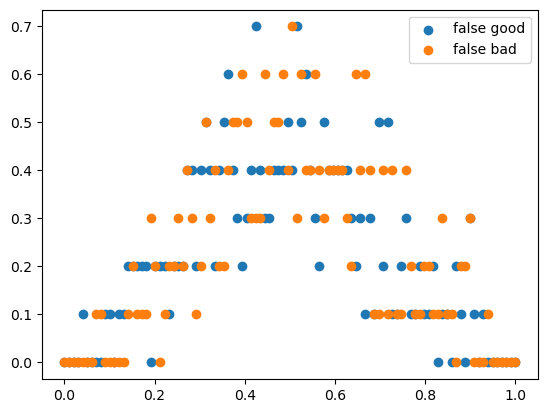

In [16]:
epsilon = 0
rest_list1 = []
rest_list2 = []
for j in range(10):
    list_1 = []
    list_2 = []
    #j = 4
    mean_norm = (mean_list[j] - min(mean_list[j])) / (max(mean_list[j]) - min(mean_list[j]))
    mean_hat_norm = (mean_hat_list1[j] - min(mean_hat_list1[j])) / (max(mean_hat_list1[j]) - min(mean_hat_list1[j]))

    for rho in np.linspace(0, 1, 100):
        good_arms = mean_hat_norm > rho
        list_1.append((mean_norm[good_arms] + epsilon <= rho).sum())
        list_2.append((mean_norm[~good_arms] - epsilon > rho).sum())
    
    rest_list1.append(list_1)
    rest_list2.append(list_2)
    #plt.scatter(np.linspace(0,1, 100), list_1)    
    
plt.scatter(np.linspace(0,1, 100), (np.array(rest_list1) > 1).mean(0), label='false good')
plt.scatter(np.linspace(0,1, 100), (np.array(rest_list2) > 1).mean(0), label='false bad')
plt.legend()

In [21]:
np.linspace(0,1, 100)

array([0.        , 0.01010101, 0.02020202, 0.03030303, 0.04040404,
       0.05050505, 0.06060606, 0.07070707, 0.08080808, 0.09090909,
       0.1010101 , 0.11111111, 0.12121212, 0.13131313, 0.14141414,
       0.15151515, 0.16161616, 0.17171717, 0.18181818, 0.19191919,
       0.2020202 , 0.21212121, 0.22222222, 0.23232323, 0.24242424,
       0.25252525, 0.26262626, 0.27272727, 0.28282828, 0.29292929,
       0.3030303 , 0.31313131, 0.32323232, 0.33333333, 0.34343434,
       0.35353535, 0.36363636, 0.37373737, 0.38383838, 0.39393939,
       0.4040404 , 0.41414141, 0.42424242, 0.43434343, 0.44444444,
       0.45454545, 0.46464646, 0.47474747, 0.48484848, 0.49494949,
       0.50505051, 0.51515152, 0.52525253, 0.53535354, 0.54545455,
       0.55555556, 0.56565657, 0.57575758, 0.58585859, 0.5959596 ,
       0.60606061, 0.61616162, 0.62626263, 0.63636364, 0.64646465,
       0.65656566, 0.66666667, 0.67676768, 0.68686869, 0.6969697 ,
       0.70707071, 0.71717172, 0.72727273, 0.73737374, 0.74747

In [19]:
(np.array(rest_list1) > 1).mean(0)

array([0. , 0. , 0. , 0. , 0.1, 0. , 0. , 0. , 0. , 0.1, 0.1, 0. , 0.1,
       0.1, 0.2, 0.2, 0.2, 0.2, 0.2, 0. , 0.2, 0.2, 0.2, 0.1, 0.2, 0.2,
       0.2, 0.4, 0.4, 0.2, 0.4, 0.5, 0.4, 0.2, 0.4, 0.5, 0.6, 0.4, 0.3,
       0.2, 0.3, 0.4, 0.7, 0.4, 0.3, 0.3, 0.4, 0.4, 0.4, 0.5, 0.4, 0.7,
       0.5, 0.6, 0.4, 0.3, 0.2, 0.5, 0.4, 0.4, 0.4, 0.4, 0.4, 0.3, 0.2,
       0.3, 0.1, 0.3, 0.1, 0.5, 0.2, 0.5, 0.1, 0.1, 0.2, 0.3, 0.1, 0.1,
       0.2, 0.1, 0.1, 0.2, 0. , 0.1, 0.1, 0. , 0.2, 0.1, 0. , 0.3, 0.1,
       0. , 0.1, 0. , 0. , 0. , 0. , 0. , 0. , 0. ])

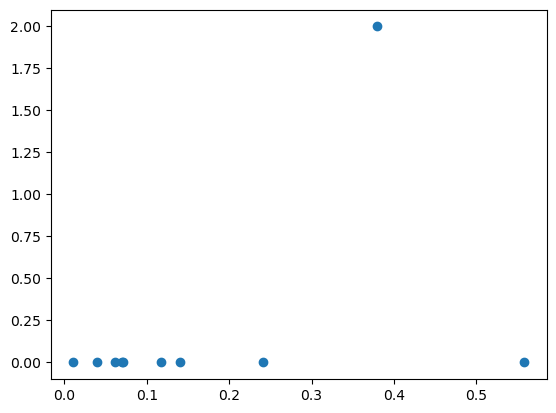

In [7]:
plt.scatter(gap_list, np.array(rest_list1)[:,4])

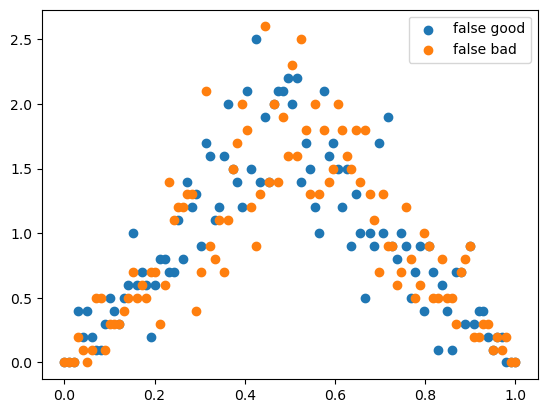

In [8]:
plt.scatter(np.linspace(0,1, 100), (np.array(rest_list1)).mean(0), label='false good')
plt.scatter(np.linspace(0,1, 100), (np.array(rest_list2)).mean(0), label='false bad')
plt.legend()

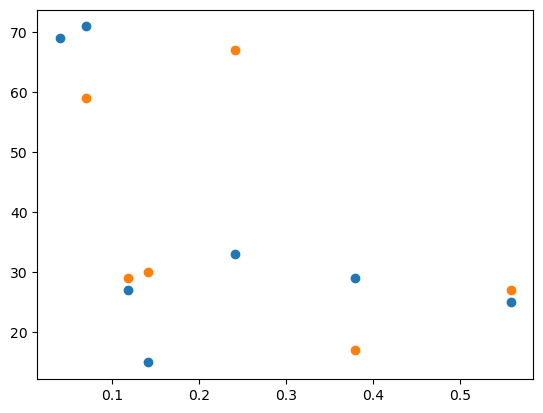

In [9]:
plt.scatter(gap_list,tau_list1)
plt.scatter(gap_list,tau_list2)
#, tau_list2

In [10]:
tau_list1

[27, 29, 25, 71, nan, 15, nan, nan, 33, 69]

In [11]:
np.nanmean(tau_list1), np.nanmean(tau_list2)

(38.42857142857143, 38.166666666666664)

In [12]:
np.mean(succ_list1), np.mean(succ_list2)

(1.0, 1.0)

In [5]:
x, y, theta = gen_data(1000, p=2, scale=10)
m, d = x.shape

prob_dict = {
        "m": m,
        "d": d,
        "x": x,
        "theta": theta,
      }

prob = linear_discover(**prob_dict)
solver = lazy_TS(prob)
reg, rwd, best, tau = solver.run(100, 0.05, 1)
tau

30

In [5]:
solver.prob.best_arm, best

(674, 674)

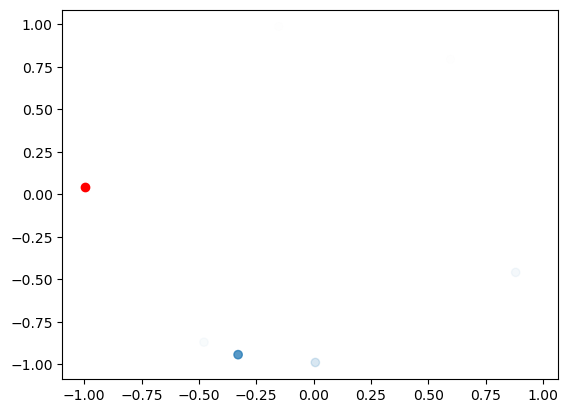

In [7]:
i=10
design = solver.design_hist[i]
plt.scatter(solver.prob.x[:,0],
            solver.prob.x[:,1],
            alpha=design)

plt.scatter(solver.prob.x[solver.prob.best_arm,0],
            solver.prob.x[solver.prob.best_arm,1],
            c='r')

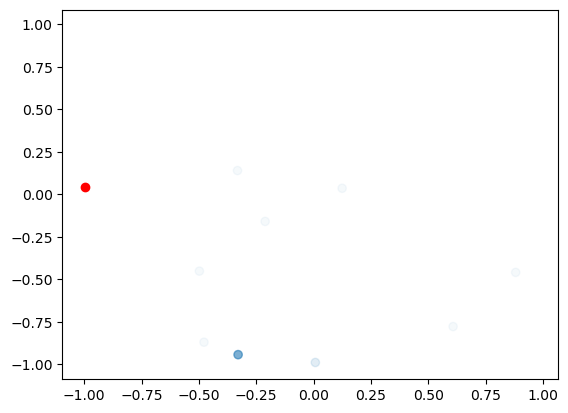

In [10]:
T = solver.prob.T_hist[10]
plt.scatter(solver.prob.x[:,0],
            solver.prob.x[:,1],
            alpha=T/sum(T))

plt.scatter(solver.prob.x[solver.prob.best_arm,0],
            solver.prob.x[solver.prob.best_arm,1],
            c='r')

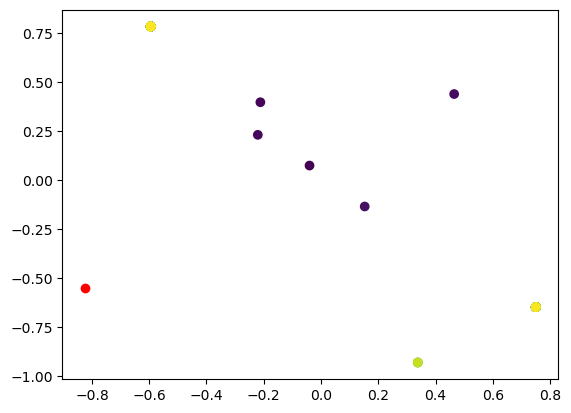

In [65]:
n = 1000
plt.scatter(solver.prob.x[solver.prob.actions,0],
            solver.prob.x[solver.prob.actions,1],
            c=np.arange(len(solver.prob.actions)))

plt.scatter(solver.prob.x[solver.prob.best_arm,0],
            solver.prob.x[solver.prob.best_arm,1],
            c='r')

In [51]:
solver.A

array([[2.66433708e+00, 5.65627561e-02],
       [5.65627561e-02, 6.00477612e+01]])

In [50]:
variable_2 = 2

In [51]:
variable, variable_2

(1, 2)

In [39]:
('design status %s, %s, %s, %s' %(1, 2, 3, 4))

'design status 1, 2, 3, 4'

In [11]:
solver._stopping_rule_1(1000,0.001)

(True,
 4.662239402994871,
 array([ 1.40146516e+00,  1.30212107e+00,  1.54267273e+00, -2.37730719e-02,
        -1.46265722e-01,  6.84522783e-01,  2.46093205e+00,  2.31466559e+00,
         1.04445837e-02, -1.59466252e+00, -3.09746066e+00,  3.67514187e+00,
         4.82794195e-01, -8.53823082e-01,  1.16410336e+00,  1.01208492e-01,
         3.07571541e+00,  2.57132772e+00,  1.70230410e+00,  1.51037613e+00,
        -6.29887293e-01, -6.07825044e-01, -3.67532334e+00,  9.44029256e-01,
         1.11369487e+00,  1.98078865e+00,  4.51360129e-02,  1.64360404e+00,
        -2.58424085e+00, -4.42118594e+00,  4.51419653e+00, -2.70769407e-01,
         1.53142709e+00,  2.09767951e+00,  3.55237220e+00,  2.78881713e+00,
        -5.46657767e-01, -1.68802234e-01,  9.71108939e-01, -1.10687407e+00,
         1.06631614e-01, -3.52474954e-01,  1.22125222e+00, -1.75135908e+00,
         5.68585236e-01, -2.19874000e+00,  7.13795933e-01, -3.92422593e+00,
        -3.36453961e+00,  5.06677220e-02,  1.04267385e+00,  6

In [6]:
best

600

In [7]:
prob.best_arm

248

In [8]:
s_ = (solver.prob.x[:,None] @ solver.sigma_hat @ solver.prob.x[:,:,None]).flatten()
((solver.mean_hat - s_)[solver.best_arm_hat] > np.delete(solver.mean_hat + s_, solver.best_arm_hat, 0)).all()

False

In [9]:
np.delete(solver.mean_hat + s_, solver.best_arm_hat, 0)

array([-2.55568918e-01,  9.55616250e+00,  1.01635177e+01,  8.26758111e+01,
        5.27670292e-01,  4.27217734e+00,  2.85119997e+01,  5.35415069e-01,
        3.90460911e+01,  3.52459737e+01,  1.61302322e+00, -2.25922668e+00,
        1.86939365e+01,  6.24585063e-01,  7.40738725e-02,  7.77153429e+00,
        2.07074079e+00,  1.76070048e+01,  5.16685881e+01,  6.48319250e+01,
        5.63220999e+00,  5.84294791e-01,  1.22343612e+01,  1.95281953e+01,
        2.75412672e+01,  6.14670245e-01,  1.21884661e+00,  7.27362732e-02,
        1.70944410e+01,  5.09595798e+00,  4.57255080e+01,  1.30379632e+01,
        9.22956949e+01,  2.38545426e+01,  2.43842281e+01,  1.97358572e+01,
        6.23498667e+00,  5.64507956e+01,  5.60990033e+01,  1.71039249e+00,
        9.88303776e+00,  8.69253857e+00,  2.90561843e+00,  1.58185559e+01,
        4.74949722e+00,  1.45071942e-01,  8.17530194e+00,  5.33298469e+00,
       -1.40089588e+00,  7.08960325e+01,  5.88061865e-02,  1.26199376e+01,
       -1.42972549e+00,  

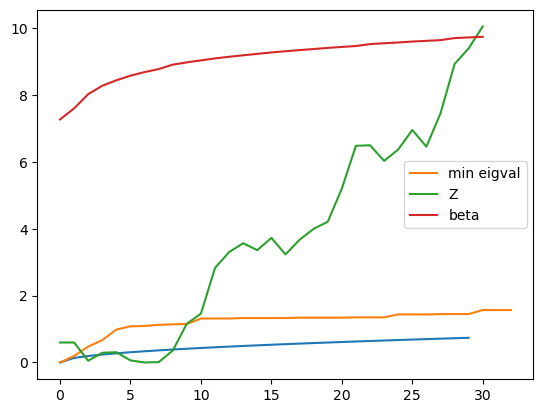

In [10]:
plt.plot(solver.c0 * np.sqrt(np.array(range(tau))), label='')
plt.plot(np.min(np.linalg.eigvals(np.cumsum([np.outer(x,x) for x in solver.prob.x[solver.prob.actions,:]],0)),1), label='min eigval')
plt.plot(solver.Z_t, label='Z')
plt.plot(solver.beta_t, label='beta')
plt.legend()

In [11]:
np.sum([np.outer(x,x) for x in solver.prob.x[solver.prob.actions,:]],0)

array([[ 18.63513283, -17.57708116],
       [-17.57708116,  16.59503884]])

In [12]:
np.linalg.pinv(solver.A)

array([[55.88101602, 59.18787918],
       [59.18787918, 62.75069109]])

In [13]:
solver.A

array([[ 18.63513283, -17.57708116],
       [-17.57708116,  16.59503884]])

In [14]:
s_ = (solver.prob.x[:,None] @ solver.sigma_hat @ solver.prob.x[:,:,None]).flatten()

In [16]:
solver.sigma_hat

array([[55.88101602, 59.18787918],
       [59.18787918, 62.75069109]])

In [17]:
order_ = np.argsort(solver.prob.x @ solver.theta_hat)[::-1]

In [6]:
plt.plot((solver.prob.x @ solver.theta_hat)[order_[:10]])
plt.plot((solver.prob.x @ solver.theta_hat - s_)[order_[:10]])
plt.plot((solver.prob.x @ solver.theta_hat + s_)[order_[:10]])

NameError: name 'order_' is not defined

In [19]:
(solver.prob.x @ solver.theta_hat - s_)[order_[0]], (solver.prob.x @ solver.theta_hat + s_)[order_[0]]

(-29.261948597467544, 35.92885346550731)

In [20]:
(solver.prob.x @ solver.theta_hat - s_)[order_[1]], (solver.prob.x @ solver.theta_hat + s_)[order_[1]]

(-60.340249391638594, 66.91694170255049)

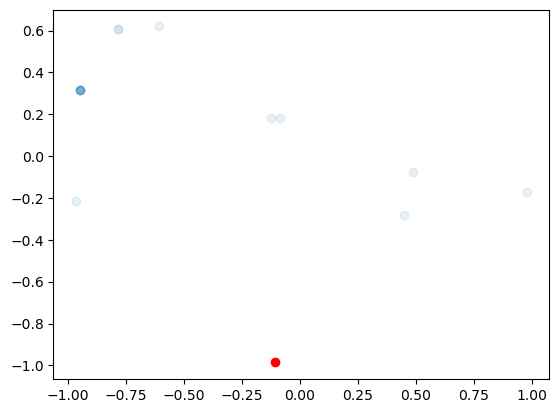

In [14]:
plt.scatter(x[solver.prob.actions,0],
            x[solver.prob.actions,1], alpha=.1)

plt.scatter(x[solver.prob.best_arm,0],
            x[solver.prob.best_arm,1], c='r')

In [62]:
rewards = solver.prob.x @ solver.theta_hat
gaps = rewards[solver.best_arm_hat] - rewards
gaps = np.delete(gaps, solver.best_arm_hat, 0)
gaps = gaps.reshape(len(gaps), 1)

np.any(gaps == 0)

Y = solver.prob.x[solver.best_arm_hat, :] - solver.prob.x
Y = np.delete(Y, solver.best_arm_hat, 0)
Y = (1/gaps)*Y
_I = np.ones((solver.prob.d, 1))
design = solver.prob.T
A_inv = np.linalg.pinv(solver.prob.x.T @ np.diag(design) @ solver.prob.x)
U, D, V = np.linalg.svd(A_inv)
Ainvhalf = U @ np.diag(np.sqrt(D)) @ V.T
newY = (Y @ Ainvhalf)**2
rho = newY @ _I
Z = (1/(2*np.max(rho)))
Z

0.0007047165974827792

In [73]:
1/(2 * np.max([x @ x.T for x in (Y @ Ainvhalf)]))

0.0007047165974827792